In [9]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('..')
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from src.dataset import get_transforms, make_loaders
from src.evaluate import predict_loader, rank_confused_pairs
from src.experiment import run_experiment, run_experiment_tl
from src.model import CNNBaseline, ResNetFromScratch, TLResNet, describe_run
from src.train import fit, make_scheduler
from src.utils import get_device, set_seed

SEED, EPOCHS, IMG_SIZE, BATCH = 42, 30, 128, 32
DATA = '../data/processed'
RESULTS = '../results/ablations.csv'
device = get_device()
paths = {
    'data': '../data/processed',
    'ckpt_dir': '../checkpoints',
    'log_dir': '../logs',
    'results': '../results/experiments.csv',
}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


✅ trues: 423, preds: 423
✅ classes: ['ambulance', 'autobus', 'kamyun', 'kamyunet', 'minibus', 'savari', 'taxi', 'vanet']


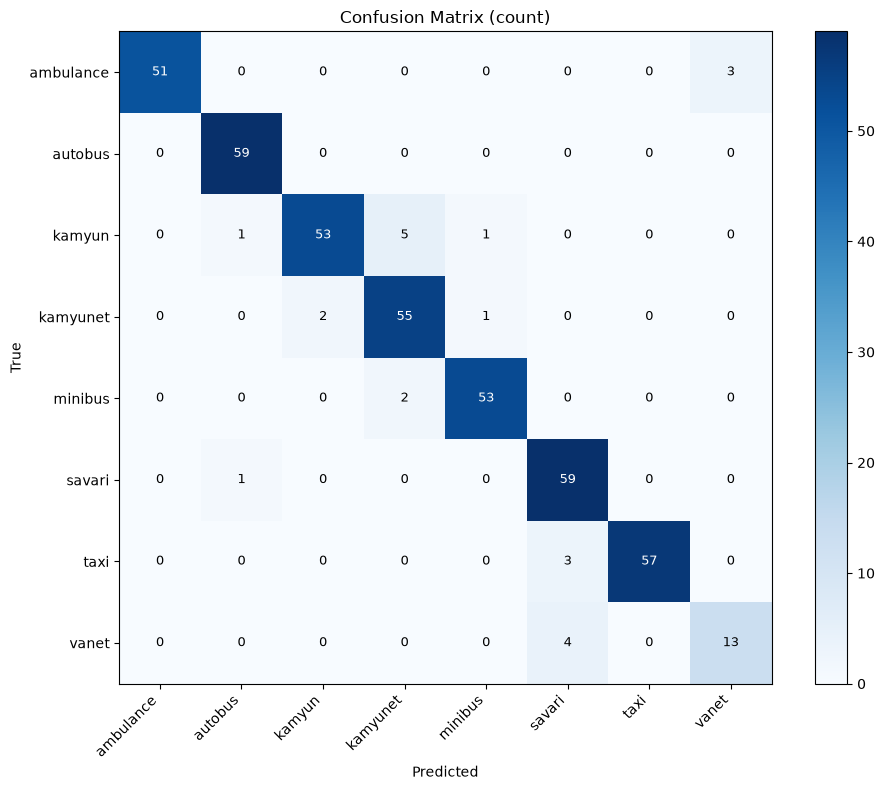

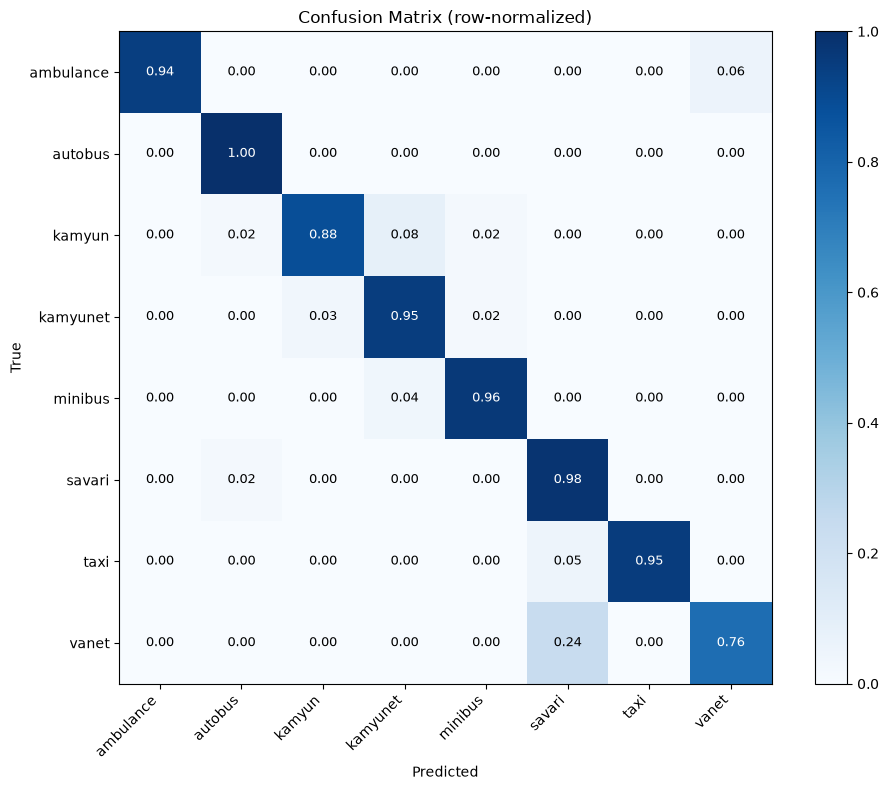


═══ Top Confused Pairs ═══
                pair  score a->b b->a
    savari <-> vanet  0.235 0/60 4/17
 kamyun <-> kamyunet  0.118 5/60 2/58
 ambulance <-> vanet  0.056 3/54 0/17
kamyunet <-> minibus  0.054 1/58 2/55
     savari <-> taxi  0.050 0/60 3/60
  autobus <-> kamyun  0.017 0/59 1/60


In [ ]:

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

val_ds = datasets.ImageFolder('../data/processed/val', transform=eval_tf)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=0)

model = TLResNet(num_classes=8, trainable=('fc', 'layer4')).to(device)
ckpt = torch.load('../checkpoints/resnet_ft.pt', weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

trues, preds = predict_loader(model, val_loader, device)
class_names = val_ds.classes
print(f" trues: {len(trues)}, preds: {len(preds)}")
print(f" classes: {class_names}")


cm = confusion_matrix(trues, preds, labels=range(len(class_names)))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

np.save('../results/cm.npy', cm)
np.save('../results/cm_norm.npy', cm_norm)


def plot_cm(cm, class_names, title='Confusion Matrix',
            fmt='d', vmax=None, save_path=None):
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=vmax)
    plt.colorbar(im, ax=ax)

    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_yticklabels(class_names)

   
    thresh = cm.max() / 2
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            if fmt == 'd':
                txt = f'{int(cm[i, j])}'
            else:
                txt = f'{cm[i, j]:.2f}'
            ax.text(j, i, txt, ha='center', va='center',
                    color='white' if cm[i, j] > thresh else 'black',
                    fontsize=9)

    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120)
    plt.show()


plot_cm(cm, class_names,
        title='Confusion Matrix (count)',
        fmt='d',
        save_path='../results/cm_count.png')


plot_cm(cm_norm, class_names,
        title='Confusion Matrix (row-normalized)',
        fmt='.2f',
        vmax=1.0,
        save_path='../results/cm_norm.png')


idx = {c: i for i, c in enumerate(class_names)}
rows = []
for a, b, score in rank_confused_pairs(cm_norm, class_names, top=6):
    i, j = idx[a], idx[b]
    rows.append({
        'pair': f'{a} <-> {b}',
        'score': round(score, 3),
        'a->b': f'{cm[i, j]}/{cm[i].sum()}',
        'b->a': f'{cm[j, i]}/{cm[j].sum()}'
    })

pairs_df = pd.DataFrame(rows)
print("\n═══ Top Confused Pairs ═══")
print(pairs_df.to_string(index=False))
pairs_df.to_csv('../results/pair_confusion.csv', index=False)

In [4]:
def merged_scores(trues, preds, class_names, groups):
    to_group = {c: g for g, members in groups.items() for c in members}
    conv = lambda i: to_group.get(class_names[i], class_names[i])
    t = [conv(i) for i in trues]
    p = [conv(i) for i in preds]
    return accuracy_score(t, p), f1_score(t, p, average='macro')

In [5]:
print('original:', accuracy_score(trues, preds), f1_score(trues, preds, average='macro'))
print('merged:  ', merged_scores(trues, preds, class_names,
                                 {'bus': ['minibus', 'autobus'], 
                                  'truck': ['kamyun', 'kamyunet']}))

original: 0.9456264775413712 0.931943720530677
merged:   (0.9621749408983451, 0.9371351196513085)


تعداد اشتباه: 23 / 423 (5.4%)


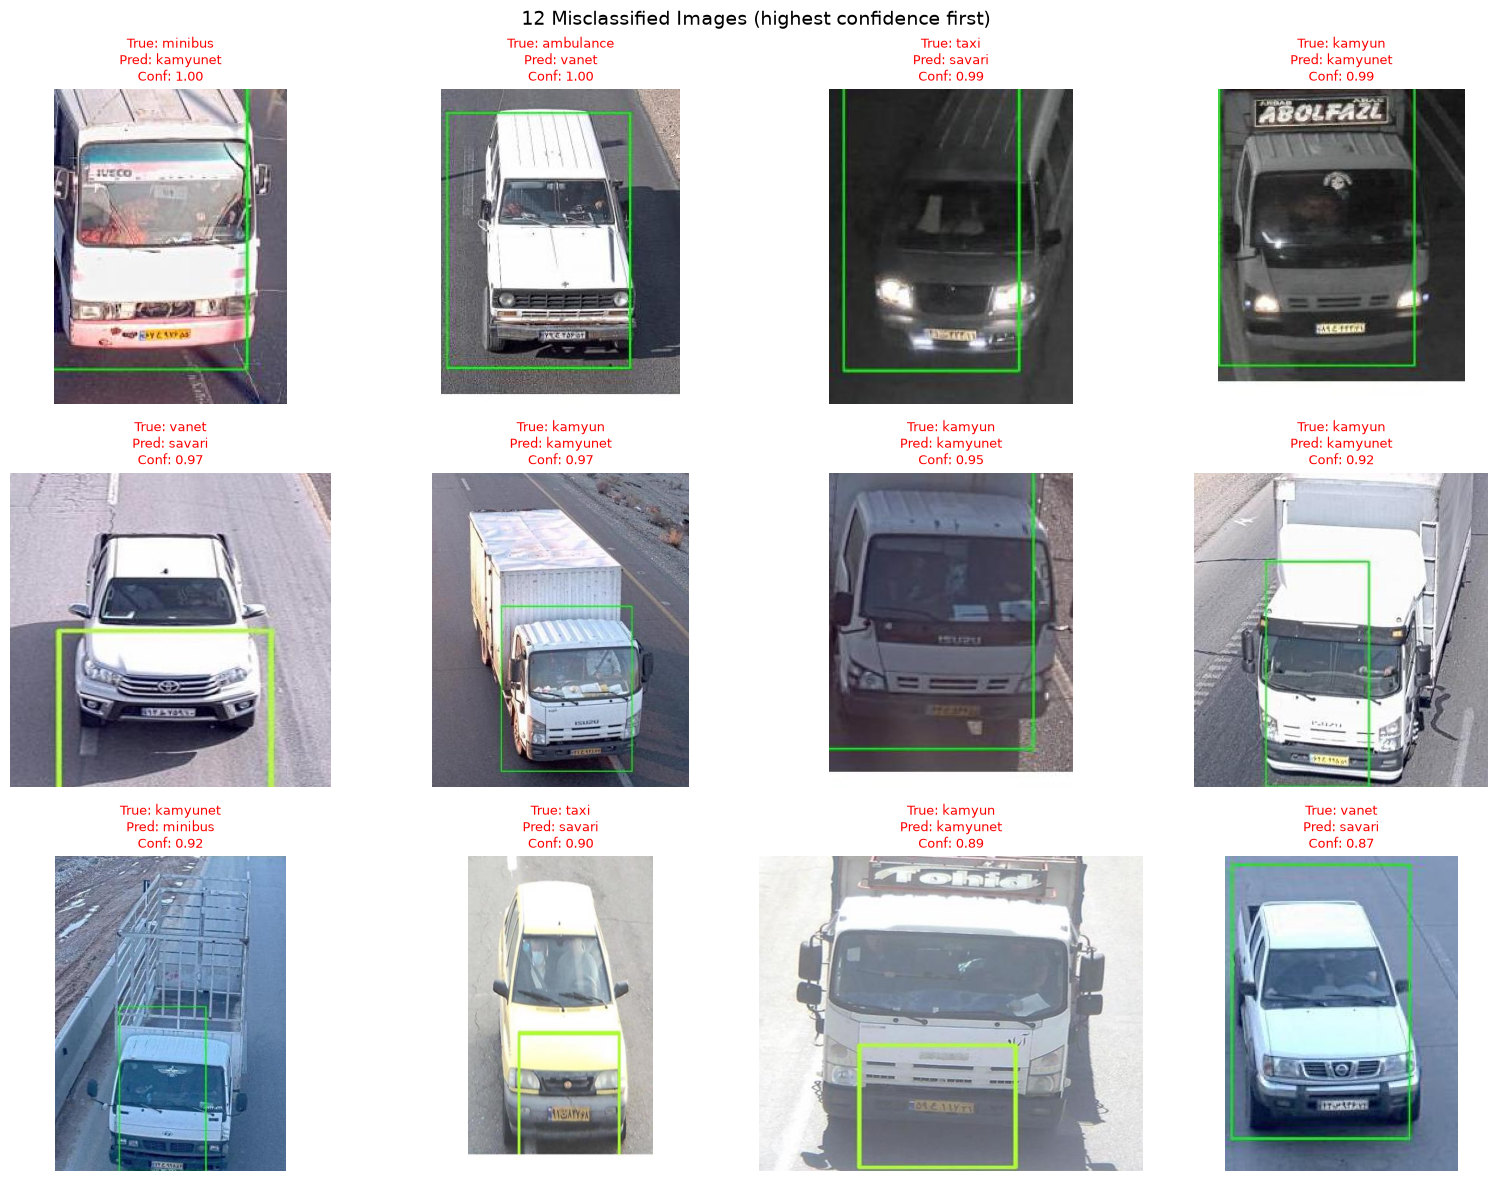

In [10]:

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
val_ds = datasets.ImageFolder('../data/processed/val', transform=eval_tf)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=0)

model = TLResNet(num_classes=8, trainable=('fc', 'layer4')).to(device)
ckpt = torch.load('../checkpoints/resnet_ft.pt', weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

trues, preds, confs = [], [], []
all_probs = []

with torch.no_grad():
    for images, targets in val_loader:
        images = images.to(device)
        logits = model(images)
        probs = torch.softmax(logits, dim=1)
        
        conf, pred = probs.max(dim=1)
        
        trues.extend(targets.tolist())
        preds.extend(pred.cpu().tolist())
        confs.extend(conf.cpu().tolist())
        all_probs.extend(probs.cpu().numpy())

trues = np.array(trues)
preds = np.array(preds)
confs = np.array(confs)
class_names = val_ds.classes

wrong_idx = np.where(trues != preds)[0]
print(f"تعداد اشتباه: {len(wrong_idx)} / {len(trues)} ({len(wrong_idx)/len(trues)*100:.1f}%)")

wrong_idx_sorted = wrong_idx[np.argsort(-confs[wrong_idx])]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, i in zip(axes.flatten(), wrong_idx_sorted[:12]):
    img_path = val_ds.samples[i][0]
    with Image.open(img_path) as img:
        ax.imshow(img)
    
    true_c = class_names[trues[i]]
    pred_c = class_names[preds[i]]
    conf = confs[i]
    
    ax.set_title(f"True: {true_c}\nPred: {pred_c}\nConf: {conf:.2f}",
                 fontsize=9,
                 color='red' if conf > 0.7 else 'orange')
    ax.axis('off')

plt.suptitle('12 Misclassified Images (highest confidence first)', fontsize=14)
plt.tight_layout()
plt.savefig('../results/misclassified_12.png', dpi=120)
plt.show()